# M05 — Exploratory Data Analysis

M04 ke cleaned Bus aur Rail data ko alag explore karte hain. Ye historical analysis hai.

## 1. Data load karo

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

bus = pd.read_csv(
    r"C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\Transit_Ridership_M10_Reviewed\transit-ridership\backend\data\processed\bus_cleaned.csv",
    dtype={"route": str}, parse_dates=["date"]
)
rail = pd.read_csv(
    r"C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\Transit_Ridership_M10_Reviewed\transit-ridership\backend\data\processed\rail_cleaned.csv",
    dtype={"station_id": str}, parse_dates=["date"]
)

datasets = {"Bus": bus, "Rail": rail}
for name, df in datasets.items():
    print(f"{name}: {len(df):,} rows, {len(df.columns)} columns")
    print("Columns:", list(df.columns))
    print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
    print("Zero rides:", (df["rides"] == 0).sum())
    print()

Bus: 167,648 rows, 4 columns
Columns: ['route', 'date', 'daytype', 'rides']
Date range: 2022-01-01 to 2025-12-31
Zero rides: 2

Rail: 209,472 rows, 5 columns
Columns: ['station_id', 'stationname', 'date', 'daytype', 'rides']
Date range: 2022-01-01 to 2025-12-31
Zero rides: 2742



## 2. Pehli 5 rows

In [2]:
bus.head()

,route,date,daytype,rides
0,1,2022-01-03,W,385
1,1,2022-01-04,W,470
2,1,2022-01-05,W,289
3,1,2022-01-06,W,339
4,1,2022-01-07,W,233


In [3]:
rail.head()

,station_id,stationname,date,daytype,rides
0,40010,Austin-Forest Park,2022-01-01,A,231
1,40020,Harlem-Lake,2022-01-01,A,500
2,40030,Pulaski-Lake,2022-01-01,A,284
3,40040,Quincy/Wells,2022-01-01,A,493
4,40050,Davis,2022-01-01,A,502


## 3. Ridership summary

Statistics ek recorded route-day ya station-day ke liye hain.

In [4]:
bus["rides"].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.99])

count    167648.000000
mean       4044.225496
std        3839.691176
min           0.000000
25%         961.000000
50%        2757.000000
75%        6141.000000
90%        9620.000000
99%       16048.530000
max       23459.000000
Name: rides, dtype: float64

In [5]:
rail["rides"].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.99])

count    209472.000000
mean       1970.937658
std        1938.233878
min           0.000000
25%         643.000000
50%        1346.000000
75%        2576.000000
90%        4470.000000
99%        9264.290000
max       26624.000000
Name: rides, dtype: float64

## 4. Monthly ridership

Har month ki recorded rides ka sum. Observation coverage aur service changes totals ko affect kar sakte hain.

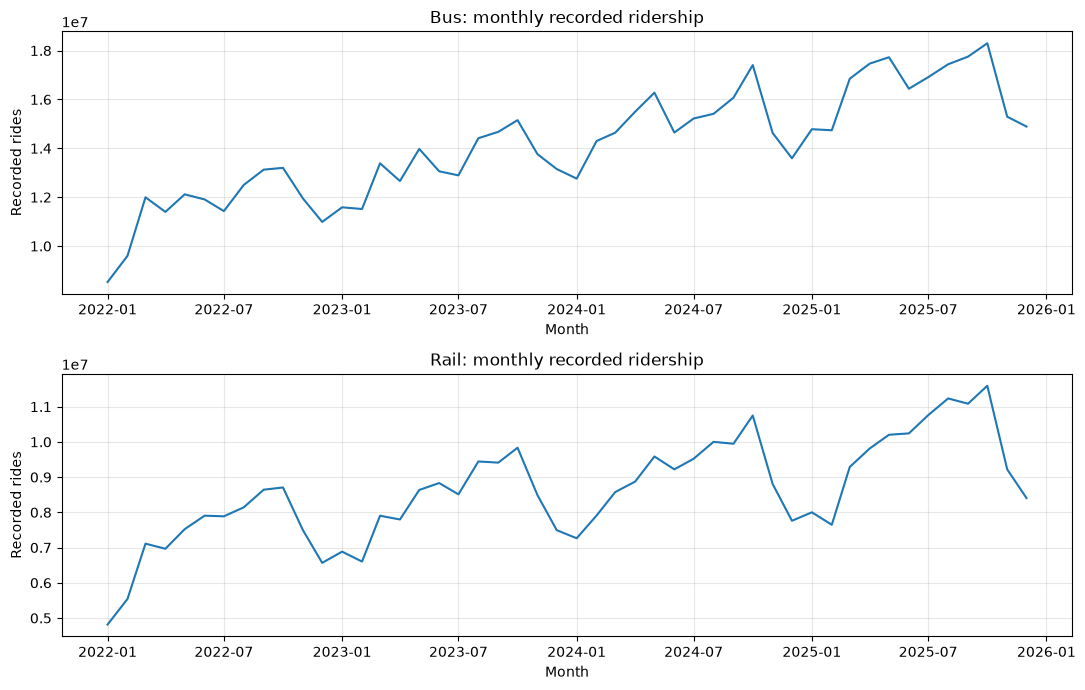

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

for ax, (name, df) in zip(axes, datasets.items()):
    monthly = df.groupby(df["date"].dt.to_period("M"))["rides"].sum()
    monthly.index = monthly.index.to_timestamp()
    ax.plot(monthly.index, monthly.values)
    ax.set_title(f"{name}: monthly recorded ridership")
    ax.set_xlabel("Month")
    ax.set_ylabel("Recorded rides")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Average rides by weekday

Average har recorded route/station row ke liye hai.

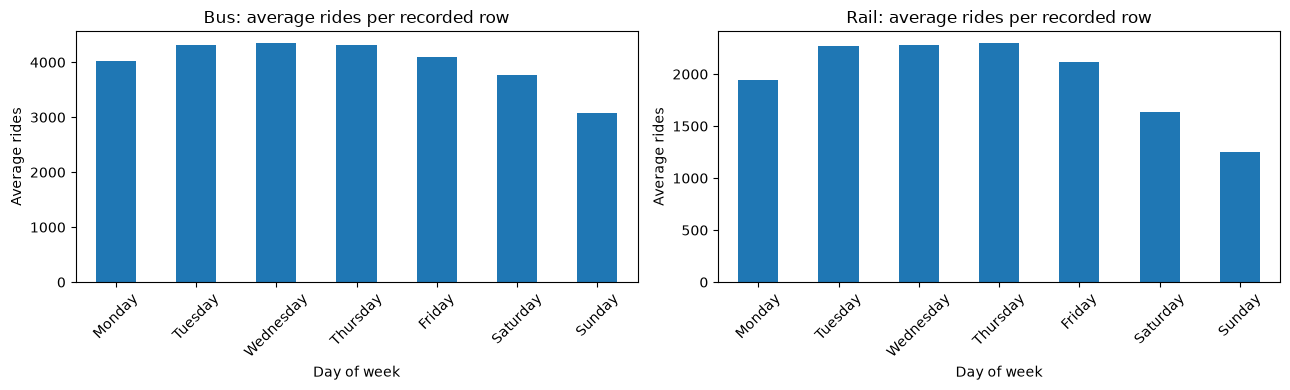

In [7]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (name, df) in zip(axes, datasets.items()):
    average = df.groupby(df["date"].dt.day_name())["rides"].mean().reindex(days)
    average.plot.bar(ax=ax)
    ax.set_title(f"{name}: average rides per recorded row")
    ax.set_xlabel("Day of week")
    ax.set_ylabel("Average rides")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 6. Ridership distribution

Chart mein 99th percentile tak ki rides hain; us se upar ki rows sirf chart se exclude hoti hain.

Bus: cutoff = 16,049, plotted = 165,971, excluded = 1,677
Rail: cutoff = 9,264, plotted = 207,377, excluded = 2,095


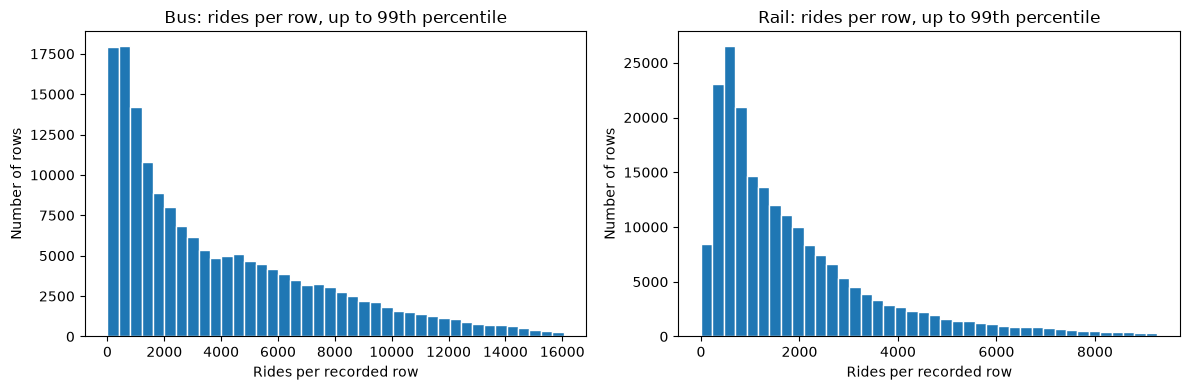

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, df) in zip(axes, datasets.items()):
    cutoff = df["rides"].quantile(0.99)
    shown = df.loc[df["rides"] <= cutoff, "rides"]
    print(f"{name}: cutoff = {cutoff:,.0f}, plotted = {len(shown):,}, excluded = {len(df) - len(shown):,}")
    ax.hist(shown, bins=40, edgecolor="white")
    ax.set_title(f"{name}: rides per row, up to 99th percentile")
    ax.set_xlabel("Rides per recorded row")
    ax.set_ylabel("Number of rows")

plt.tight_layout()
plt.show()

## 7. Top routes aur stations

`recorded_days` se pata chalta hai average kitne recorded days se bana hai.

In [9]:
bus_top = bus.groupby("route")["rides"].agg(
    average_rides="mean", recorded_days="count"
).sort_values("average_rides", ascending=False).head(10).round({"average_rides": 1})

bus_top

,average_rides,recorded_days
route,,
66,13909.6,1461
9,13107.2,1461
79,13041.6,1461
8,12278.8,1461
53,11765.8,1461
77,11209.4,1461
22,10929.8,1461
49,10782.1,1461
3,10736.6,1461


In [10]:
rail_top = rail.groupby("station_id")["rides"].agg(
    average_rides="mean", recorded_days="count"
).sort_values("average_rides", ascending=False).head(10).round({"average_rides": 1})

rail_top

,average_rides,recorded_days
station_id,,
41660,8793.9,1461
40890,7935.1,1461
40380,7339.5,1461
41450,6552.3,1461
40260,6521.5,1461
41220,6465.6,1461
41400,6182.3,1461
41320,6106.2,1461
40370,5972.2,1461


Bus route boardings aur Rail station entries alag measures hain. Ye charts capacity, overcrowding ya future demand prove nahi karte.